In [31]:
from environment7 import *
from agent8 import *
import torch
import numpy as np
import matplotlib.pyplot as plt

# U_LIST = np.arange(48, 101, 12)
U_LIST = np.arange(12, 121, 12)
# U_LIST = np.arange(70,90,2)

P_PA_FIXED = 0.1
NUM_EVAL_EPISODES = 10

CKPT_PATH = "DIPSM1_ep15000.pth"

# =====================================================
# Metric storage
# =====================================================

thpt_drl2 = []
ee_drl2 = []
power_drl2 = []
ibo_drl2 = []
dist_drl2 = []

all_drl_ep_rates2 = []
all_drl_ep_ee2 = []
all_drl_ep_power2 = []
all_drl_ep_ibo2 = []
all_drl_ep_dist2 = []

# =====================================================
# Store every episode's power matrix
# =====================================================

all_pmat2 = {}

device = "cuda" if torch.cuda.is_available() else "cpu"

# =====================================================
# Load checkpoint once
# =====================================================

checkpoint = torch.load(CKPT_PATH, map_location=device)

for U in U_LIST:

    print(f"Evaluating DRL for U = {U}")

    env = Env4(
        use_distortion=True,
        use_sm=True,
        U=U,
        P_pa=P_PA_FIXED
    )

    state_dim = env.observation_space.shape[0]
    num_rbs = env.N * env.M

    agent = Agent1(state_dim, num_rbs, device=device)

    # Restore network
    agent.qnet.load_state_dict(checkpoint["qnet_state_dict"])
    agent.qtarget.load_state_dict(checkpoint["qtarget_state_dict"])

    # Greedy policy
    agent.epsilon = 0.0

    # Evaluation mode
    agent.qnet.eval()
    agent.qtarget.eval()

    ep_rates = []
    ep_ee = []
    ep_power = []
    ep_ibo = []
    ep_dist = []

    # Store pmat for every episode
    pmat_list = []

    for ep in range(NUM_EVAL_EPISODES):

        state, _ = env.reset()

        done = False

        while not done:

            with torch.no_grad():
                action = agent.get_action(state)

            next_state, reward, terminated, truncated, _ = env.step(action)

            state = next_state
            done = terminated or truncated

        # ==========================================
        # Save power allocation matrix
        # ==========================================
        pmat_list.append(env.pmat.copy())

        # ==========================================
        # Final-step metrics
        # ==========================================
        P_ru = np.sum(env.pmat, axis=1)

        avg_ru_power = np.mean(P_ru)
        P_avg_ant = P_ru / env.Nt
        avg_ibo = np.mean(env.P_pa / (P_avg_ant + 1e-12))

        ep_rates.append(env.DR[-1])
        ep_ee.append(env.EE[-1])
        ep_power.append(avg_ru_power)
        ep_ibo.append(avg_ibo)
        ep_dist.append(env.distortion_power)

    # ==========================================
    # Store all power matrices for this U
    # Shape: (NUM_EVAL_EPISODES, N, M)
    # ==========================================
    all_pmat2[U] = np.stack(pmat_list, axis=0)

    thpt_drl2.append(np.mean(ep_rates))
    ee_drl2.append(np.mean(ep_ee))
    power_drl2.append(np.mean(ep_power))
    ibo_drl2.append(np.mean(ep_ibo))
    dist_drl2.append(np.mean(ep_dist))

    all_drl_ep_rates2.append(ep_rates)
    all_drl_ep_ee2.append(ep_ee)
    all_drl_ep_power2.append(ep_power)
    all_drl_ep_ibo2.append(ep_ibo)
    all_drl_ep_dist2.append(ep_dist)

    # =====================================================
    # Save progress after each U
    # =====================================================
    
#     np.savez(
#         "evaluation_results2.npz",
    
#         thpt_drl2=np.array(thpt_drl2),
#         ee_drl2=np.array(ee_drl2),
#         power_drl2=np.array(power_drl2),
#         ibo_drl2=np.array(ibo_drl2),
#         dist_drl2=np.array(dist_drl2),
    
#         all_drl_ep_rates2=np.array(all_drl_ep_rates2, dtype=object),
#         all_drl_ep_ee2=np.array(all_drl_ep_ee2, dtype=object),
#         all_drl_ep_power2=np.array(all_drl_ep_power2, dtype=object),
#         all_drl_ep_ibo2=np.array(all_drl_ep_ibo2, dtype=object),
#         all_drl_ep_dist2=np.array(all_drl_ep_dist2, dtype=object),
    
#         all_pmat2=np.array(all_pmat2, dtype=object)
#     )

# print(f"Saved results through U = {U}")

# =====================================================
# Convert to numpy arrays
# =====================================================

thpt_drl2 = np.array(thpt_drl2)
ee_drl2 = np.array(ee_drl2)
power_drl2 = np.array(power_drl2)
ibo_drl2 = np.array(ibo_drl2)
dist_drl2 = np.array(dist_drl2)

/tmp/ipykernel_86/517265228.py:44: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CKPT_PATH, map_location=device)


Evaluating DRL for U = 12
Evaluating DRL for U = 24
Evaluating DRL for U = 36
Evaluating DRL for U = 48
Evaluating DRL for U = 60
Evaluating DRL for U = 72
Evaluating DRL for U = 84
Evaluating DRL for U = 96
Evaluating DRL for U = 108
Evaluating DRL for U = 120


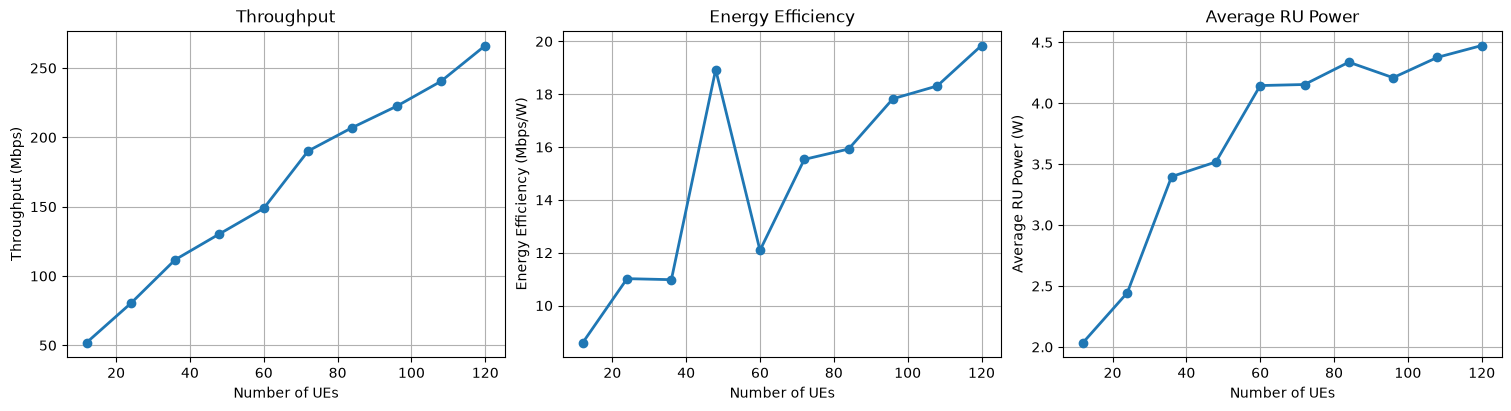

In [32]:
# =====================================================
# Metrics vs Number of UEs
# =====================================================

# U_LIST = np.arange(12, 121, 12)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

# Throughput
axes[0].plot(U_LIST, thpt_drl2, marker='o', linewidth=2)
axes[0].set_xlabel("Number of UEs")
axes[0].set_ylabel("Throughput (Mbps)")
axes[0].set_title("Throughput")
axes[0].grid(True)

# Energy Efficiency
axes[1].plot(U_LIST, ee_drl2, marker='o', linewidth=2)
axes[1].set_xlabel("Number of UEs")
axes[1].set_ylabel("Energy Efficiency (Mbps/W)")
axes[1].set_title("Energy Efficiency")
axes[1].grid(True)

# Average RU Power
axes[2].plot(U_LIST, power_drl2, marker='o', linewidth=2)
axes[2].set_xlabel("Number of UEs")
axes[2].set_ylabel("Average RU Power (W)")
axes[2].set_title("Average RU Power")
axes[2].grid(True)

plt.show()

In [103]:
# # =====================================================
# # Save everything
# # =====================================================
# import numpy as np
# import matplotlib.pyplot as plt

# np.savez(
#     "evaluation_results15k.npz",

#     thpt_drl2=thpt_drl2,
#     ee_drl2=ee_drl2,
#     power_drl2=power_drl2,
#     ibo_drl2=ibo_drl2,
#     dist_drl2=dist_drl2,

#     all_drl_ep_rates2=np.array(all_drl_ep_rates2, dtype=object),
#     all_drl_ep_ee2=np.array(all_drl_ep_ee2, dtype=object),
#     all_drl_ep_power2=np.array(all_drl_ep_power2, dtype=object),
#     all_drl_ep_ibo2=np.array(all_drl_ep_ibo2, dtype=object),
#     all_drl_ep_dist2=np.array(all_drl_ep_dist2, dtype=object),

#     all_pmat2=np.array(all_pmat2, dtype=object)
# )

# print("Evaluation complete.")
# print("Results saved to evaluation_results15k.npz")

In [1]:
import numpy as np
import matplotlib.pyplot as plt
data = np.load("evaluation_results15k.npz", allow_pickle=True)

thpt_drl2 = data["thpt_drl2"]
ee_drl2 = data["ee_drl2"]
power_drl2 = data["power_drl2"]
ibo_drl2 = data["ibo_drl2"]
dist_drl2 = data["dist_drl2"]

all_drl_ep_rates2 = data["all_drl_ep_rates2"]
all_drl_ep_ee2 = data["all_drl_ep_ee2"]
all_drl_ep_power2 = data["all_drl_ep_power2"]
all_drl_ep_ibo2 = data["all_drl_ep_ibo2"]
all_drl_ep_dist2 = data["all_drl_ep_dist2"]

all_pmat2 = data["all_pmat2"].item()

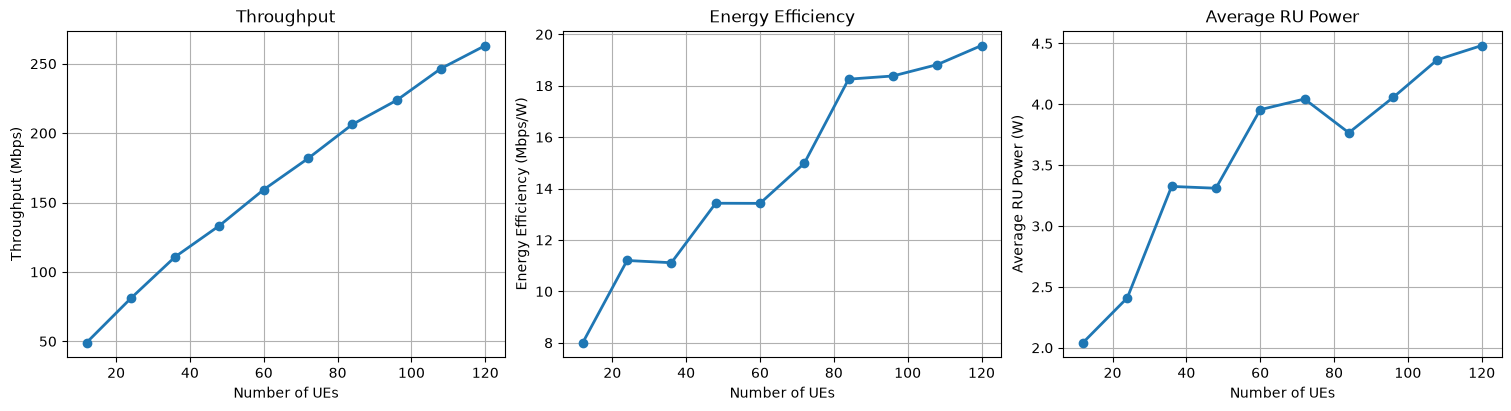

In [7]:
# =====================================================
# Metrics vs Number of UEs
# =====================================================

U_LIST = np.arange(12, 121, 12)
ee_drl2 = thpt_drl2 / (3 * np.array([np.mean(p) for p in all_drl_ep_power2]))


fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

# Throughput
axes[0].plot(U_LIST, thpt_drl2, marker='o', linewidth=2)
axes[0].set_xlabel("Number of UEs")
axes[0].set_ylabel("Throughput (Mbps)")
axes[0].set_title("Throughput")
axes[0].grid(True)

# Energy Efficiency
axes[1].plot(U_LIST, ee_drl2, marker='o', linewidth=2)
axes[1].set_xlabel("Number of UEs")
axes[1].set_ylabel("Energy Efficiency (Mbps/W)")
axes[1].set_title("Energy Efficiency")
axes[1].grid(True)

# Average RU Power
axes[2].plot(U_LIST, power_drl2, marker='o', linewidth=2)
axes[2].set_xlabel("Number of UEs")
axes[2].set_ylabel("Average RU Power (W)")
axes[2].set_title("Average RU Power")
axes[2].grid(True)

plt.show()

# # =====================================================
# # IBO
# # =====================================================

# plt.figure(figsize=(6,4))
# plt.plot(U_LIST, ibo_drl2, marker='o', linewidth=2)
# plt.xlabel("Number of UEs")
# plt.ylabel("Average IBO")
# plt.grid(True)
# plt.tight_layout()

# # =====================================================
# # Distortion Power
# # =====================================================

# plt.figure(figsize=(6,4))
# plt.plot(U_LIST, dist_drl2, marker='o', linewidth=2)
# plt.xlabel("Number of UEs")
# plt.ylabel("Average Distortion Power (W)")
# plt.grid(True)
# plt.tight_layout()

## =====================================================
## Heatmaps for every U
## =====================================================


# for U in U_LIST:

#     avg_pmat = all_pmat2[U].mean(axis=0)

#     plt.figure(figsize=(6,3))

#     im = plt.imshow(
#         avg_pmat,
#         origin="lower",
#         aspect="auto",
#         cmap="viridis"
#     )

#     plt.colorbar(im, label="Average Power (W)")

#     plt.xlabel("Resource Block")
#     plt.ylabel("Radio Unit")

#     plt.xticks(np.arange(avg_pmat.shape[1]))
#     plt.yticks(
#         np.arange(avg_pmat.shape[0]),
#         [f"RU {i}" for i in range(avg_pmat.shape[0])]
#     )

#     plt.title(f"Average RB Power Allocation (U={U})")

#     plt.tight_layout()

# plt.show()

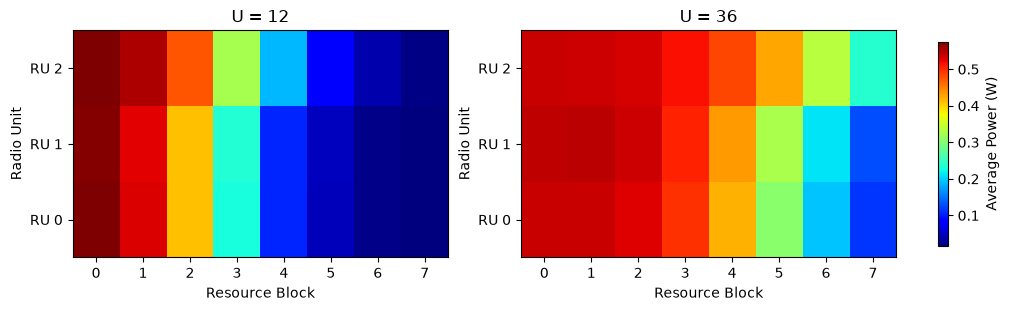

In [20]:
U_LIST = [12,36]

fig, axes = plt.subplots(1, len(U_LIST), figsize=(5 * len(U_LIST), 3), constrained_layout=True)

if len(U_LIST) == 1:
    axes = [axes]

vmin = min(all_pmat2[U].mean(axis=0).min() for U in U_LIST)
vmax = max(all_pmat2[U].mean(axis=0).max() for U in U_LIST)

for ax, U in zip(axes, U_LIST):

    avg_pmat = all_pmat2[U].mean(axis=0)

    im = ax.imshow(
        avg_pmat,
        origin="lower",
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f"U = {U}")
    ax.set_xlabel("Resource Block")
    ax.set_ylabel("Radio Unit")
    ax.set_xticks(np.arange(avg_pmat.shape[1]))
    ax.set_yticks(np.arange(avg_pmat.shape[0]))
    ax.set_yticklabels([f"RU {i}" for i in range(avg_pmat.shape[0])])

cbar = fig.colorbar(im, ax=axes, shrink=0.9)
cbar.set_label("Average Power (W)")

plt.show()

In [36]:
print(f"{'U':>5} {'Throughput':>12} {'Power':>12} {'Thpt/Power':>15} {'EE':>12} {'Difference':>12}")

for U, th, pw, ee in zip(U_LIST, thpt_drl2, power_drl2, ee_drl2):
    ratio = th / pw
    diff = ee - ratio
    print(f"{U:5d} {th:12.4f} {pw:12.4f} {ratio:15.4f} {ee:12.4f} {diff:12.6f}")

    U   Throughput        Power      Thpt/Power           EE   Difference
   12      51.9357       2.0354         25.5162       8.5972   -16.919067
   24      80.3141       2.4449         32.8501      11.0188   -21.831328
   36     111.7407       3.3981         32.8836      10.9803   -21.903296
   48     130.3565       3.5184         37.0496      18.9311   -18.118494
   60     148.8083       4.1452         35.8987      12.0899   -23.808719
   72     190.1380       4.1539         45.7734      15.5329   -30.240455
   84     207.0986       4.3372         47.7494      15.9248   -31.824600
   96     222.4711       4.2098         52.8460      17.8267   -35.019265
  108     240.4455       4.3768         54.9364      18.3118   -36.624535
  120     266.2430       4.4738         59.5116      19.8422   -39.669453


In [34]:
print(f"{'U':>5} {'Thpt':>10} {'AvgRU':>10} {'3*AvgRU':>10} {'Thpt/(3P)':>12} {'EE':>10}")

for U, th, pw, ee in zip(U_LIST, thpt_drl2, power_drl2, ee_drl2):
    print(f"{U:5d} {th:10.3f} {pw:10.3f} {3*pw:10.3f} {th/(3*pw):12.3f} {ee:10.3f}")

    U       Thpt      AvgRU    3*AvgRU    Thpt/(3P)         EE
   12     51.936      2.035      6.106        8.505      8.597
   24     80.314      2.445      7.335       10.950     11.019
   36    111.741      3.398     10.194       10.961     10.980
   48    130.356      3.518     10.555       12.350     18.931
   60    148.808      4.145     12.436       11.966     12.090
   72    190.138      4.154     12.462       15.258     15.533
   84    207.099      4.337     13.012       15.916     15.925
   96    222.471      4.210     12.629       17.615     17.827
  108    240.446      4.377     13.130       18.312     18.312
  120    266.243      4.474     13.421       19.837     19.842


In [16]:
print(thpt_drl2)

[ 49.05627294  80.99908788 110.89085112 133.37340169 159.31674814
 181.75236708 206.2725852  223.65249121 246.5308718  263.10605647]


In [35]:
print(ee_drl2)

[ 8.5971656  11.01878213 10.9803038  18.93108323 12.08993926 15.53292361
 15.92477001 17.82674311 18.31183803 19.84215396]


In [18]:
print(power_drl2)

[2.04242007 2.41025493 3.32550953 3.31058773 3.95599873 4.04350373
 3.76643887 4.05618447 4.36626113 4.4827634 ]


In [37]:
ee_avg = thpt_drl2 / (3 * np.array([np.mean(p) for p in all_drl_ep_power2]))

print(ee_avg)

[ 8.50541094 10.95003681 10.96120002 12.34985893 11.96621928 15.25779298
 15.9164568  17.61533609 18.31212446 19.83720246]


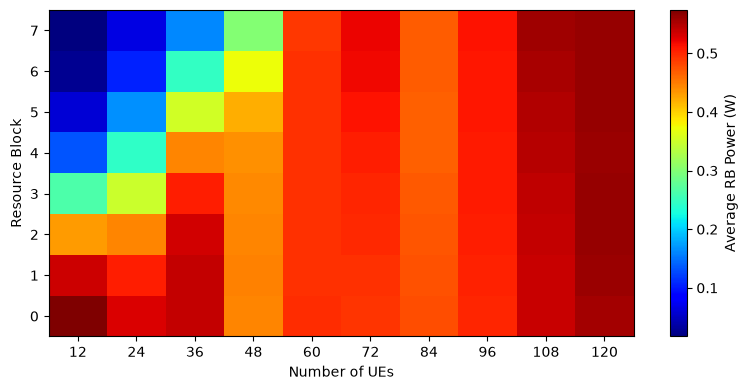

In [21]:
import numpy as np
import matplotlib.pyplot as plt

U_LIST = sorted(all_pmat2.keys())

# Shape after averaging:
# all_pmat2[U] : (episodes, N_RU, N_RB)
# -> mean over episodes and RUs -> (N_RB,)

power_map = np.array([
    all_pmat2[U].mean(axis=(0, 1))
    for U in U_LIST
]).T   # Shape: (N_RB, len(U_LIST))

plt.figure(figsize=(8, 4))

im = plt.imshow(
    power_map,
    origin="lower",
    aspect="auto",
    cmap="jet"
)

plt.xlabel("Number of UEs")
plt.ylabel("Resource Block")

plt.xticks(np.arange(len(U_LIST)), U_LIST)
plt.yticks(np.arange(power_map.shape[0]))

cbar = plt.colorbar(im)
cbar.set_label("Average RB Power (W)")

plt.tight_layout()
plt.show()

In [2]:
print(thpt_drl2)
print(ee_drl2)

[ 49.05627294  80.99908788 110.89085112 133.37340169 159.31674814
 181.75236708 206.2725852  223.65249121 246.5308718  263.10605647]
[ 8.16815728 11.42583126 11.46538873 21.20139802 14.70710951 15.50727512
 20.65452826 21.85143159 18.82036962 19.5669269 ]
